# Practice 04 — ML General Tips

**Goal:** answer three questions that come up after a model is trained.

| Question | Tool |
|:---|:---|
| Is accuracy telling me the truth? | confusion matrix, precision / recall, ROC |
| How much of the variation does my regression explain? | $R^2$ |
| Why is it wrong — too simple, or too unstable? | bias–variance decomposition |

---
## Imports

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'   # must be set before sklearn is imported

import numpy as np
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.datasets import load_diabetes, load_digits, make_friedman1
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge, LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score,
                             roc_curve, roc_auc_score, r2_score)

np.random.seed(42)
plt.rcParams['axes.unicode_minus'] = False

---
# 1. Classification Metrics

## The Whole Evaluation in One Cell

- Task → **is this image a 3?** (binary labels from `digits`, about one image in ten is a 3)
- Split → train / validation / test: the validation set is kept for choosing a threshold later
- Train → infer → score; the sections below take the confusion matrix and the ROC curve apart

train 1077, validation 360, test 360
accuracy  0.9917
precision 0.9722
recall    0.9459
f1        0.9589
roc auc   0.9979


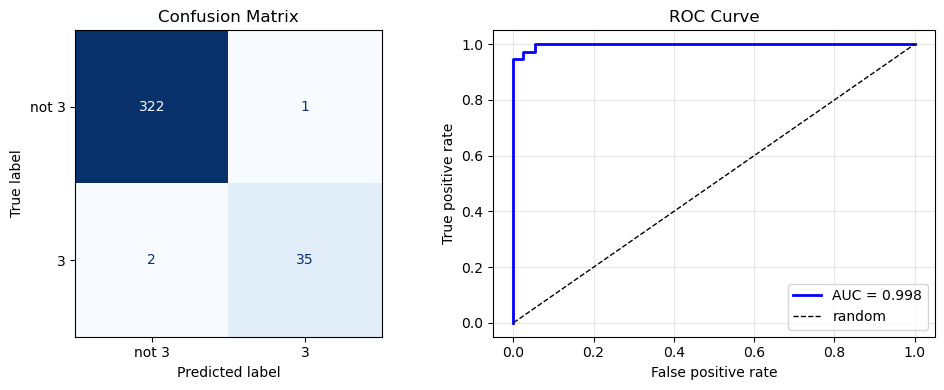

In [2]:
# ---- data
digits = load_digits()
y_binary = (digits.target == 3).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    digits.data, y_binary, test_size=0.2, random_state=42, stratify=y_binary)

# validation set: kept aside for choosing a threshold
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42, stratify=y_train)

print(f'train {len(y_train)}, validation {len(y_val)}, test {len(y_test)}')

# ---- training
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42))
model.fit(X_train, y_train)

# ---- inference
y_pred = model.predict(X_test)                # labels, thresholded at 0.5
score  = model.predict_proba(X_test)[:, 1]    # the probability behind that threshold

# ---- metrics
auc = roc_auc_score(y_test, score)

print(f'accuracy  {accuracy_score(y_test, y_pred):.4f}')
print(f'precision {precision_score(y_test, y_pred):.4f}')
print(f'recall    {recall_score(y_test, y_pred):.4f}')
print(f'f1        {f1_score(y_test, y_pred):.4f}')
print(f'roc auc   {auc:.4f}')

# ---- the two standard plots
matrix = confusion_matrix(y_test, y_pred)
fpr, tpr, thresholds = roc_curve(y_test, score)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

matrix_display = ConfusionMatrixDisplay(matrix, display_labels=['not 3', '3'])
matrix_display.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Confusion Matrix')

axes[1].plot(fpr, tpr, 'b-', linewidth=2, label=f'AUC = {auc:.3f}')
axes[1].plot([0, 1], [0, 1], 'k--', linewidth=1, label='random')
axes[1].set_xlabel('False positive rate')
axes[1].set_ylabel('True positive rate')
axes[1].set_title('ROC Curve')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

---
## Confusion Matrix, Precision, Recall

| | predicted 0 | predicted 1 |
|:---|:---|:---|
| **actual 0** | TN | FP (false alarm) |
| **actual 1** | FN (missed) | TP |

$$\text{precision} = \frac{TP}{TP + FP}, \qquad
\text{recall} = \frac{TP}{TP + FN}, \qquad F_1 = \frac{2 \cdot \text{precision} \cdot
\text{recall}}{\text{precision} + \text{recall}}$$

- Low precision → false alarms, low recall → misses
- Cost decides which matters → a missed blade crack vs. an unnecessary inspection

In [3]:
# matrix[row, column]: row = actual, column = predicted
tn = matrix[0, 0]
fp = matrix[0, 1]
fn = matrix[1, 0]
tp = matrix[1, 1]
print(f'TN {tn}, FP {fp}, FN {fn}, TP {tp}')

precision = precision_score(y_test, y_pred)
recall    = recall_score(y_test, y_pred)
precision_manual = tp / (tp + fp)
recall_manual    = tp / (tp + fn)

print(f'precision          {precision:.4f}')
print(f'precision (manual) {precision_manual:.4f}')
print(f'recall             {recall:.4f}')
print(f'recall (manual)    {recall_manual:.4f}')

TN 322, FP 1, FN 2, TP 35
precision          0.9722
precision (manual) 0.9722
recall             0.9459
recall (manual)    0.9459


---
## ROC and AUC

$$TPR = \frac{TP}{TP + FN} \;(= \text{recall}), \qquad FPR = \frac{FP}{FP + TN}$$

- `accuracy`, `precision`, `recall` → judge the *labels*: `predict` cuts the score at **0.5**
- ROC curve → TPR against FPR as the cut moves; AUC → the area under it, independent of any single cut

### A 2-Pixel Model

- Same pipeline, but it sees only two of the 64 pixels → nothing else differs

In [4]:
two_pixels = [21, 42]
model_2px = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42))
model_2px.fit(X_train[:, two_pixels], y_train)

y_pred_2px = model_2px.predict(X_test[:, two_pixels])
score_2px  = model_2px.predict_proba(X_test[:, two_pixels])[:, 1]
auc_2px = roc_auc_score(y_test, score_2px)

print('64 pixels')
print(f'  accuracy  {accuracy_score(y_test, y_pred):.4f}')
print(f'  precision {precision_score(y_test, y_pred):.4f}')
print(f'  recall    {recall_score(y_test, y_pred):.4f}')
print(f'  f1        {f1_score(y_test, y_pred):.4f}')

print('2 pixels')
print(f'  accuracy  {accuracy_score(y_test, y_pred_2px):.4f}')
print(f'  precision {precision_score(y_test, y_pred_2px, zero_division=0):.4f}')
print(f'  recall    {recall_score(y_test, y_pred_2px):.4f}')
print(f'  f1        {f1_score(y_test, y_pred_2px, zero_division=0):.4f}')

64 pixels
  accuracy  0.9917
  precision 0.9722
  recall    0.9459
  f1        0.9589
2 pixels
  accuracy  0.8972
  precision 0.0000
  recall    0.0000
  f1        0.0000


- 2 pixels → precision and recall **0** at threshold 0.5: no 3 is predicted at all (precision 0/0, reported as 0 by `zero_division=0`)
- Accuracy 0.90 is then just the share of non-3s in the test set

### Score Distributions

- Counts of the `predict_proba` scores on the test set, by true class (323 non-3s, 37 3s) → where does each model put the 3s?

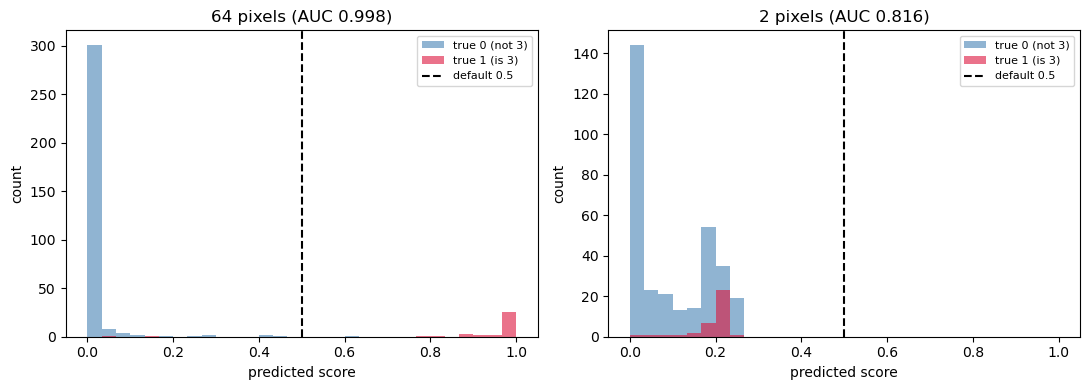

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bins = np.linspace(0, 1, 31)

axes[0].hist(score[y_test == 0], bins=bins, alpha=0.6, color='steelblue', label='true 0 (not 3)')
axes[0].hist(score[y_test == 1], bins=bins, alpha=0.6, color='crimson', label='true 1 (is 3)')
axes[0].axvline(0.5, color='k', linestyle='--', linewidth=1.5, label='default 0.5')
axes[0].set_title(f'64 pixels (AUC {auc:.3f})')

axes[1].hist(score_2px[y_test == 0], bins=bins, alpha=0.6, color='steelblue', label='true 0 (not 3)')
axes[1].hist(score_2px[y_test == 1], bins=bins, alpha=0.6, color='crimson', label='true 1 (is 3)')
axes[1].axvline(0.5, color='k', linestyle='--', linewidth=1.5, label='default 0.5')
axes[1].set_title(f'2 pixels (AUC {auc_2px:.3f})')

for ax in axes:
    ax.set_xlabel('predicted score')
    ax.set_ylabel('count')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

- **64 pixels** → the two classes sit at opposite ends, almost no overlap
- **2 pixels** → heavy overlap and every score below 0.5, so no 3 is predicted at the default cut
- The 3s still sit slightly to the right → that shift alone is worth AUC 0.82

### ROC Curves

- The same two models as ROC curves → the area under each curve is its AUC

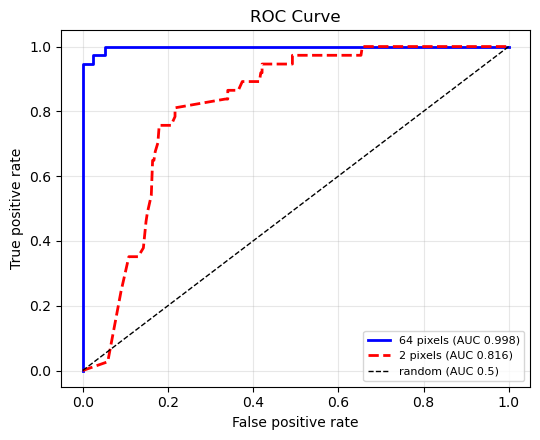

In [6]:
fpr_2px, tpr_2px, thresholds_2px = roc_curve(y_test, score_2px)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.plot(fpr, tpr, 'b-', linewidth=2, label=f'64 pixels (AUC {auc:.3f})')
ax.plot(fpr_2px, tpr_2px, 'r--', linewidth=2,
        label=f'2 pixels (AUC {auc_2px:.3f})')
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='random (AUC 0.5)')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_title('ROC Curve')
ax.legend(fontsize=8, loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- **64 pixels** → TPR 0.95 already at FPR 0: the curve hugs the top-left corner
- **2 pixels** → TPR 0.8 costs FPR ≈ 0.2, a fifth of the non-3s flagged

### AUC by Counting Pairs

$$\text{AUC} = P\bigl(\,\text{score of a random 3} > \text{score of a random non-3}\,\bigr)$$

- `positives` → the 37 test 3s as a column `(37, 1)`; `negatives` → the 323 other digits as a row `(1, 323)`
- `positives > negatives` → numpy compares every pair: entry `[i, j]` is True when the i-th 3 outscores the j-th non-3
- AUC = share of True cells; `sum()` counts each True as 1 (64-pixel model)

In [7]:
positives = score[y_test == 1].reshape(-1, 1)    # (37, 1); -1 = as many rows as needed
negatives = score[y_test == 0].reshape(1, -1)    # (1, 323)

pairs = positives > negatives                    # (37, 323) table of True / False
n_true = pairs.sum()
auc_manual = n_true / pairs.size

print(f'pairs        {pairs.shape}, True in {n_true} of {pairs.size}')
print(f'AUC          {auc:.4f}')
print(f'AUC (manual) {auc_manual:.4f}')

pairs        (37, 323), True in 11926 of 11951
AUC          0.9979
AUC (manual) 0.9979


- Only 25 of 11951 pairs are False → the few 3s that scored near 0 in the histogram

---
## Choosing the Threshold t

| Rule | Picks the t with |
|:---|:---|
| **Youden's J** | the largest J = TPR − FPR, the point farthest above the diagonal |
| **max F1** | the best balance of precision and recall |

- Every point of the ROC curve = one threshold t
- t is a hyperparameter → chosen on the **validation** set, then reported once on test

### 64 Pixels

- Validation scores → ROC curve → the threshold where J is largest
- One F1 score per candidate threshold → the threshold where F1 is largest

In [8]:
score_val = model.predict_proba(X_val)[:, 1]
fpr_val, tpr_val, thresholds_val = roc_curve(y_val, score_val)

# Youden's J at every threshold
youden_j = tpr_val - fpr_val
youden_threshold = thresholds_val[np.argmax(youden_j)]

# F1 at every threshold
f1_values = []
for threshold in thresholds_val:
    y_pred_val = (score_val >= threshold).astype(int)
    f1 = f1_score(y_val, y_pred_val, zero_division=0)
    f1_values.append(f1)
max_f1_threshold = thresholds_val[np.argmax(f1_values)]

print('64 pixels')
print(f'  Youden threshold {youden_threshold:.3f}')
print(f'  max-F1 threshold {max_f1_threshold:.3f}')

64 pixels
  Youden threshold 0.094
  max-F1 threshold 0.560


### 2 Pixels

- The same steps on the 2-pixel model

In [9]:
score_val_2px = model_2px.predict_proba(X_val[:, two_pixels])[:, 1]
fpr_val_2px, tpr_val_2px, thresholds_val_2px = roc_curve(y_val, score_val_2px)

youden_j_2px = tpr_val_2px - fpr_val_2px
youden_threshold_2px = thresholds_val_2px[np.argmax(youden_j_2px)]

f1_values_2px = []
for threshold in thresholds_val_2px:
    y_pred_val = (score_val_2px >= threshold).astype(int)
    f1 = f1_score(y_val, y_pred_val, zero_division=0)
    f1_values_2px.append(f1)
max_f1_threshold_2px = thresholds_val_2px[np.argmax(f1_values_2px)]

print('2 pixels')
print(f'  Youden threshold {youden_threshold_2px:.3f}')
print(f'  max-F1 threshold {max_f1_threshold_2px:.3f}')

2 pixels
  Youden threshold 0.179
  max-F1 threshold 0.183


### Where the Chosen t Cuts

- The test-set histograms again, now with both chosen thresholds

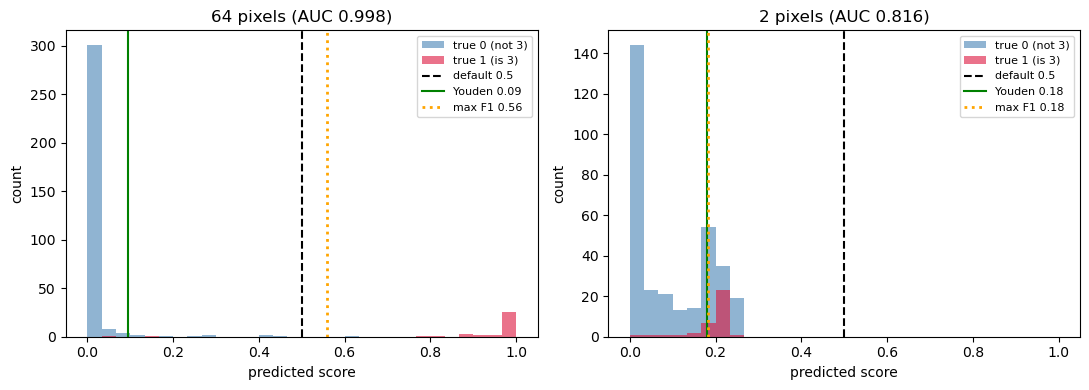

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bins = np.linspace(0, 1, 31)

axes[0].hist(score[y_test == 0], bins=bins, alpha=0.6, color='steelblue', label='true 0 (not 3)')
axes[0].hist(score[y_test == 1], bins=bins, alpha=0.6, color='crimson', label='true 1 (is 3)')
axes[0].axvline(0.5, color='k', linestyle='--', linewidth=1.5, label='default 0.5')
axes[0].axvline(youden_threshold, color='green', linestyle='-', linewidth=1.5, label=f'Youden {youden_threshold:.2f}')
axes[0].axvline(max_f1_threshold, color='orange', linestyle=':', linewidth=2, label=f'max F1 {max_f1_threshold:.2f}')
axes[0].set_title(f'64 pixels (AUC {auc:.3f})')

axes[1].hist(score_2px[y_test == 0], bins=bins, alpha=0.6, color='steelblue', label='true 0 (not 3)')
axes[1].hist(score_2px[y_test == 1], bins=bins, alpha=0.6, color='crimson', label='true 1 (is 3)')
axes[1].axvline(0.5, color='k', linestyle='--', linewidth=1.5, label='default 0.5')
axes[1].axvline(youden_threshold_2px, color='green', linestyle='-', linewidth=1.5, label=f'Youden {youden_threshold_2px:.2f}')
axes[1].axvline(max_f1_threshold_2px, color='orange', linestyle=':', linewidth=2, label=f'max F1 {max_f1_threshold_2px:.2f}')
axes[1].set_title(f'2 pixels (AUC {auc_2px:.3f})')

for ax in axes:
    ax.set_xlabel('predicted score')
    ax.set_ylabel('count')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

- **64 pixels** → Youden 0.09 sits just above the non-3 peak; max F1 0.56 sits in the empty gap, so it cuts like 0.5
- **2 pixels** → both rules cut through the overlap at almost the same t

### Test Set at the Chosen Thresholds

- Compare with the threshold-0.5 results under **A 2-Pixel Model**

In [11]:
y_pred_youden = (score >= youden_threshold).astype(int)
y_pred_max_f1 = (score >= max_f1_threshold).astype(int)

print(f'64 pixels, Youden threshold {youden_threshold:.3f}')
print(f'  accuracy  {accuracy_score(y_test, y_pred_youden):.4f}')
print(f'  precision {precision_score(y_test, y_pred_youden):.4f}')
print(f'  recall    {recall_score(y_test, y_pred_youden):.4f}')
print(f'  f1        {f1_score(y_test, y_pred_youden):.4f}')

print(f'64 pixels, max-F1 threshold {max_f1_threshold:.3f}')
print(f'  accuracy  {accuracy_score(y_test, y_pred_max_f1):.4f}')
print(f'  precision {precision_score(y_test, y_pred_max_f1):.4f}')
print(f'  recall    {recall_score(y_test, y_pred_max_f1):.4f}')
print(f'  f1        {f1_score(y_test, y_pred_max_f1):.4f}')

64 pixels, Youden threshold 0.094
  accuracy  0.9694
  precision 0.7826
  recall    0.9730
  f1        0.8675
64 pixels, max-F1 threshold 0.560
  accuracy  0.9917
  precision 0.9722
  recall    0.9459
  f1        0.9589


In [12]:
y_pred_2px_youden = (score_2px >= youden_threshold_2px).astype(int)
y_pred_2px_max_f1 = (score_2px >= max_f1_threshold_2px).astype(int)

print(f'2 pixels, Youden threshold {youden_threshold_2px:.3f}')
print(f'  accuracy  {accuracy_score(y_test, y_pred_2px_youden):.4f}')
print(f'  precision {precision_score(y_test, y_pred_2px_youden):.4f}')
print(f'  recall    {recall_score(y_test, y_pred_2px_youden):.4f}')
print(f'  f1        {f1_score(y_test, y_pred_2px_youden):.4f}')

print(f'2 pixels, max-F1 threshold {max_f1_threshold_2px:.3f}')
print(f'  accuracy  {accuracy_score(y_test, y_pred_2px_max_f1):.4f}')
print(f'  precision {precision_score(y_test, y_pred_2px_max_f1):.4f}')
print(f'  recall    {recall_score(y_test, y_pred_2px_max_f1):.4f}')
print(f'  f1        {f1_score(y_test, y_pred_2px_max_f1):.4f}')

2 pixels, Youden threshold 0.179
  accuracy  0.7833
  precision 0.2929
  recall    0.7838
  f1        0.4265
2 pixels, max-F1 threshold 0.183
  accuracy  0.7889
  precision 0.2947
  recall    0.7568
  f1        0.4242


- 2 pixels, threshold 0.5 → 0.18: recall 0 → 0.78, precision 0.29; both rules pick almost the same t
- 64 pixels, Youden 0.09: precision 0.97 → 0.78, F1 0.96 → 0.87; max F1 0.56 keeps the 0.5 result → **"optimal" depends on the criterion**
- **AUC ranks, it does not decide** → unchanged wherever the threshold goes

---
# 2. Regression Metrics — $R^2$

## Three Levels of Fit

$$R^2 = 1 - \frac{SSE}{SST}, \qquad SSE = \sum_i (y_i - \hat{y}_i)^2, \qquad SST = \sum_i (y_i - \bar{y})^2$$

- $SST$ → variation to explain, $SSE$ → what the model leaves unexplained
- $R^2 = 1$ → perfect fit, $R^2 = 0$ → always predicting the mean, $R^2 < 0$ (possible on test data) → worse than the mean

### Three Noisy Copies of One Line

- Three sets from the **same straight line** $y = 5 + 2x$, only the noise differs

In [13]:
rng = np.random.RandomState(42)
x = rng.uniform(-3, 3, (120, 1))
noise = rng.normal(0, 1, (120, 1))

y1 = 5 + 2 * x + 1.15 * noise
y2 = 5 + 2 * x + 2.0 * noise
y3 = 5 + 2 * x + 3.5 * noise

print(f'x: {x.shape}, y: {y1.shape}')

x: (120, 1), y: (120, 1)


### Fit and Plot

- One `LinearRegression` per set → $R^2$ from `r2_score`, shown in each panel title

In [14]:
model1 = LinearRegression()
model1.fit(x, y1)
y1_hat = model1.predict(x)

model2 = LinearRegression()
model2.fit(x, y2)
y2_hat = model2.predict(x)

model3 = LinearRegression()
model3.fit(x, y3)
y3_hat = model3.predict(x)

r2_1 = r2_score(y1, y1_hat)
r2_2 = r2_score(y2, y2_hat)
r2_3 = r2_score(y3, y3_hat)

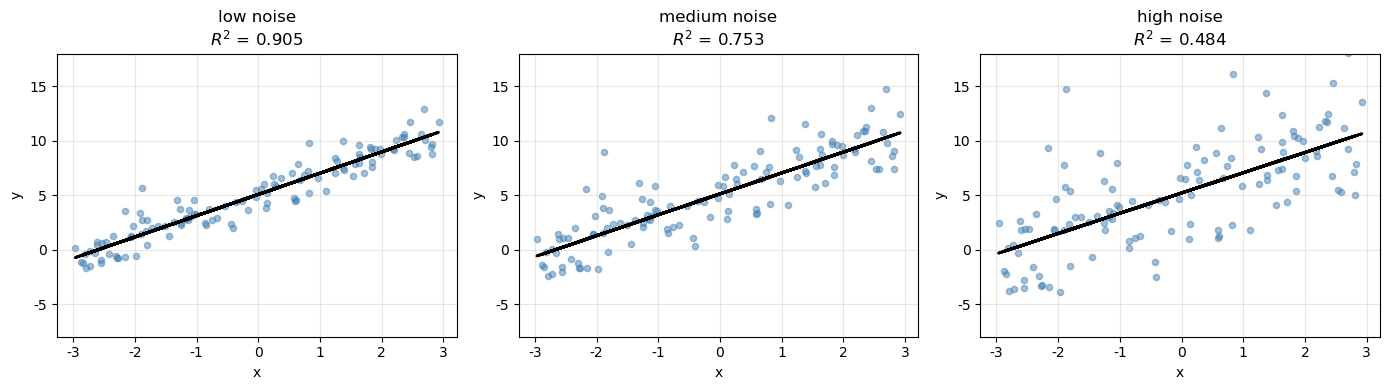

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].scatter(x, y1, s=20, alpha=0.5, c='steelblue')
axes[0].plot(x, y1_hat, 'k-', linewidth=2)
axes[0].set_title(f'low noise\n$R^2$ = {r2_1:.3f}')

axes[1].scatter(x, y2, s=20, alpha=0.5, c='steelblue')
axes[1].plot(x, y2_hat, 'k-', linewidth=2)
axes[1].set_title(f'medium noise\n$R^2$ = {r2_2:.3f}')

axes[2].scatter(x, y3, s=20, alpha=0.5, c='steelblue')
axes[2].plot(x, y3_hat, 'k-', linewidth=2)
axes[2].set_title(f'high noise\n$R^2$ = {r2_3:.3f}')

for ax in axes:
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_ylim(-8, 18)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Same underlying line, more scatter → $R^2$ 0.91, 0.75, 0.48 (fit and scored on the same 120 points)
- The model is right every time → **a low $R^2$ does not mean a wrong model**

---
## Computing $R^2$ by Hand

- First set `y1` → $SST$ and $SSE$, then `r2_score` with the definition $1 - SSE/SST$ printed below it

In [16]:
y_mean = y1.mean()
SST = ((y1 - y_mean) ** 2).sum()
SSE = ((y1 - y1_hat) ** 2).sum()
r2_manual = 1 - SSE / SST

print(f'SST          {SST:.2f}')
print(f'SSE          {SSE:.2f}')
print(f'R^2          {r2_1:.6f}')
print(f'R^2 (manual) {r2_manual:.6f}')

SST          1603.84
SSE          151.94
R^2          0.905262
R^2 (manual) 0.905262


---
# 3. Bias and Variance

## The Decomposition

$$\mathbb{E}\bigl[(y - \hat{\theta})^2\bigr] = \underbrace{\mathbb{E}\bigl[(y - \theta)^2\bigr]}_{\text{data variance}}
+ \underbrace{\bigl(\theta - \mathbb{E}[\hat{\theta}]\bigr)^2}_{\text{bias}^2}
+ \underbrace{\mathbb{E}\bigl[(\hat{\theta} - \mathbb{E}[\hat{\theta}])^2\bigr]}_{\text{variance}}$$

| Term | Means | Cause |
|:---|:---|:---|
| data variance | measurements $y$ scatter around the truth $\theta$ | noise; no model removes it |
| bias² | average prediction is off the truth | too rigid |
| variance | prediction $\hat{\theta}$ moves with the training set | too flexible, fitting noise |

### Bootstrap

- Same model, many training sets → at one $x$ the predictions $\hat{\theta}$ form a distribution
- One training set only → resample with replacement, refit, use the spread of the predictions

In [17]:
def bias_variance_decomposition(estimator, X_train, y_train, X_test, y_reference, n_rounds=40, seed=42):
    # refit on n_rounds bootstrap resamples and split the squared error at each test point
    rng = np.random.RandomState(seed)
    predictions = np.zeros((n_rounds, len(X_test)))

    for r in range(n_rounds):
        index = rng.randint(0, len(X_train), len(X_train))    # sample with replacement
        refitted = clone(estimator)                           # a fresh, unfitted copy each round
        refitted.fit(X_train[index], y_train[index])
        predictions[r] = refitted.predict(X_test)

    mean_prediction = predictions.mean(axis=0)
    bias_squared = np.mean((y_reference - mean_prediction) ** 2)
    variance     = np.mean(predictions.var(axis=0))
    return bias_squared, variance

---
## The Trade-off

- `make_friedman1` → the ground truth $\theta$ is a known formula, so predictions are scored against $\theta$, not $y$
- Data variance then drops out → only bias² and variance remain
- Complexity = depth of a regression tree

In [18]:
X_friedman, y_friedman = make_friedman1(n_samples=600, n_features=10, noise=1.0, random_state=0)
X_train_friedman, X_test_friedman, y_train_friedman, _ = train_test_split(
    X_friedman, y_friedman, test_size=0.3, random_state=0)

def friedman_truth(X):
    # the noiseless function behind make_friedman1
    return 10 * np.sin(np.pi * X[:, 0] * X[:, 1]) + 20 * (X[:, 2] - 0.5) ** 2 + 10 * X[:, 3] + 5 * X[:, 4]

y_true_friedman = friedman_truth(X_test_friedman)    # ground truth theta at the test inputs

depths = np.arange(1, 13)
bias_curve = []
variance_curve = []
total_curve = []
for depth in depths:
    tree = DecisionTreeRegressor(max_depth=depth, random_state=0)
    bias_squared, variance = bias_variance_decomposition(
        tree, X_train_friedman, y_train_friedman, X_test_friedman, y_true_friedman)
    bias_curve.append(bias_squared)
    variance_curve.append(variance)
    total_curve.append(bias_squared + variance)

best_depth = depths[np.argmin(total_curve)]

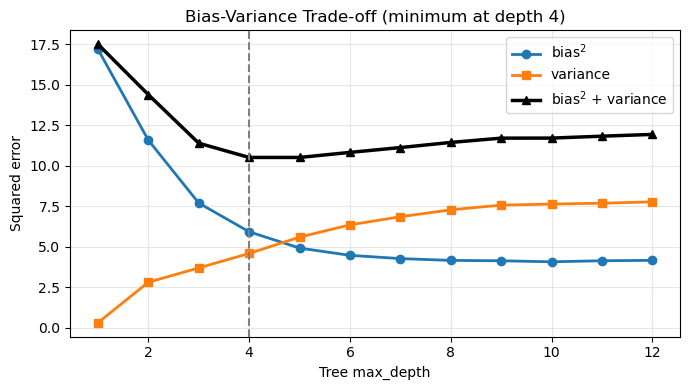

In [19]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(depths, bias_curve, 'o-', linewidth=2, label='bias$^2$')
ax.plot(depths, variance_curve, 's-', linewidth=2, label='variance')
ax.plot(depths, total_curve, 'k^-', linewidth=2.5, label='bias$^2$ + variance')
ax.axvline(best_depth, color='gray', linestyle='--', linewidth=1.5)
ax.set_xlabel('Tree max_depth')
ax.set_ylabel('Squared error')
ax.set_title(f'Bias-Variance Trade-off (minimum at depth {best_depth})')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- bias² → falls fast, then levels off from about depth 7: more depth no longer brings the average prediction closer
- variance → keeps rising: deeper trees decide each region from fewer points
- Total → lowest around depth 4, then up again: overfitting

---
## Two Remedies: Averaging and Shrinkage

- Real data → `diabetes`: 442 patients, 10 measurements; $\theta$ unknown → scored against $y$, so the first number is bias² + data variance (the same data variance for every model)
- **Averaging** → one unlimited tree vs. a Random Forest of 100 such trees
- **Shrinkage** → plain linear regression vs. Ridge, the same linear model with a penalty

In [20]:
diabetes = load_diabetes()
X_train_diabetes, X_test_diabetes, y_train_diabetes, y_test_diabetes = train_test_split(
    diabetes.data, diabetes.target, test_size=0.3, random_state=0)

tree_unlimited = DecisionTreeRegressor(random_state=0)
forest         = RandomForestRegressor(n_estimators=100, random_state=0, n_jobs=-1)
linear         = make_pipeline(StandardScaler(), LinearRegression())
ridge          = make_pipeline(StandardScaler(), Ridge(alpha=5.0))

In [21]:
bias_squared, variance = bias_variance_decomposition(
    tree_unlimited, X_train_diabetes, y_train_diabetes, X_test_diabetes, y_test_diabetes)
print('Tree (unlimited)')
print(f'  bias^2 + data variance {bias_squared:7.1f}')
print(f'  variance               {variance:7.1f}')

bias_squared, variance = bias_variance_decomposition(
    forest, X_train_diabetes, y_train_diabetes, X_test_diabetes, y_test_diabetes)
print('Random Forest (100 trees)')
print(f'  bias^2 + data variance {bias_squared:7.1f}')
print(f'  variance               {variance:7.1f}')

bias_squared, variance = bias_variance_decomposition(
    linear, X_train_diabetes, y_train_diabetes, X_test_diabetes, y_test_diabetes)
print('Linear regression')
print(f'  bias^2 + data variance {bias_squared:7.1f}')
print(f'  variance               {variance:7.1f}')

bias_squared, variance = bias_variance_decomposition(
    ridge, X_train_diabetes, y_train_diabetes, X_test_diabetes, y_test_diabetes)
print('Ridge (alpha=5)')
print(f'  bias^2 + data variance {bias_squared:7.1f}')
print(f'  variance               {variance:7.1f}')

Tree (unlimited)
  bias^2 + data variance  3655.4
  variance                3051.6


Random Forest (100 trees)
  bias^2 + data variance  3399.0
  variance                 322.3
Linear regression
  bias^2 + data variance  3104.9
  variance                  94.5
Ridge (alpha=5)
  bias^2 + data variance  3112.2
  variance                  83.4


- **Averaging** → variance 3052 → 322, a tenth; bias² + data variance also lower (3655 → 3399)
- **Shrinkage** → variance 94.5 → 83.4, bias² + data variance slightly up (3105 → 3112): a little bias for less variance
- The linear models start with far lower variance than the trees → the trees need the remedy more

---
## Summary

| Metric | Blind to |
|:---|:---|
| accuracy | class imbalance |
| precision | the ones missed |
| recall | the false alarms |
| ROC AUC | the threshold you deploy |
| $R^2$ | whether the model is right |

- The AUC 0.82 model → no 3 found at 0.5, recall 0.78 at the Youden threshold chosen on validation
- $R^2$ fell from 0.91 to 0.48 on an equally correct model → only the noise changed
- bias² high → too simple; variance high → fitting noise